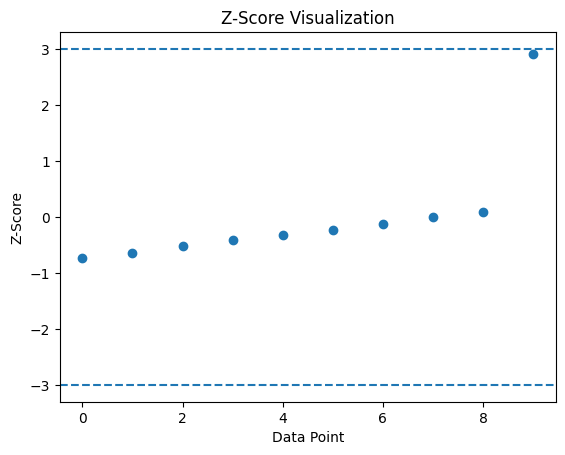

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Visualization")

plt.show()

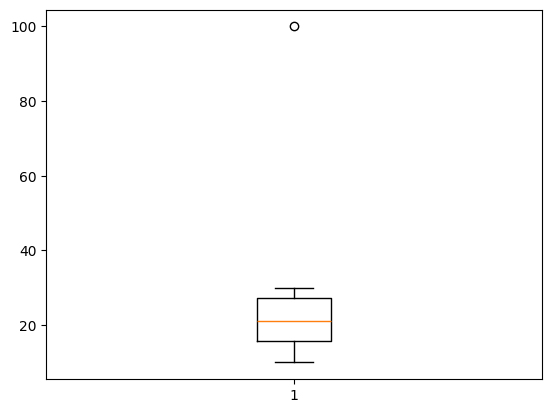

In [4]:
plt.boxplot(data)
plt.show()

In [20]:
import seaborn as sns
import pandas as pd 

df=sns.load_dataset('tips')

In [21]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [27]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x1c0a85af9d0>,
 'caps': [<matplotlib.lines.Line2D at 0x1c0a85afc50>,
 'boxes': [<matplotlib.lines.Line2D at 0x1c0a85af890>],
 'medians': [<matplotlib.lines.Line2D at 0x1c0a85afed0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1c0a85f0050>],
 'means': []}

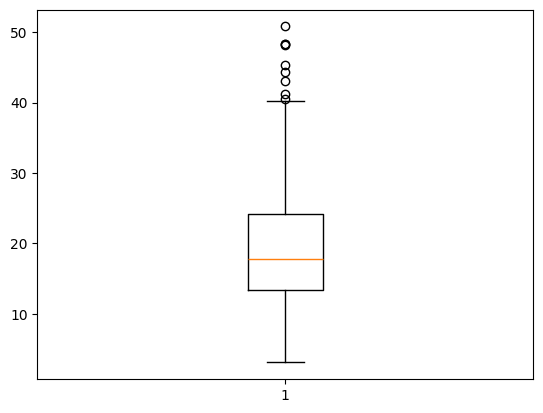

In [26]:
plt.boxplot(df['total_bill'])

In [22]:
q1 = df['total_bill'].quantile(0.25)
q3 = df['total_bill'].quantile(0.75)
iqr = q3-q1
print('iqr ----' , iqr)

iqr ---- 10.779999999999998


In [23]:
q1 = df['total_bill'].quantile(0.25)
q3 = df['total_bill'].quantile(0.75)
iqr = q3-q1

lower = q1-1.5*iqr

upper = q3+1.5*iqr

df1=df[(df['total_bill']<upper) & (df['total_bill']>lower)]

{'whiskers': [<matplotlib.lines.Line2D at 0x1c0a8626350>,
 'caps': [<matplotlib.lines.Line2D at 0x1c0a86265d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1c0a8626210>],
 'medians': [<matplotlib.lines.Line2D at 0x1c0a8626850>],
 'fliers': [<matplotlib.lines.Line2D at 0x1c0a8626990>],
 'means': []}

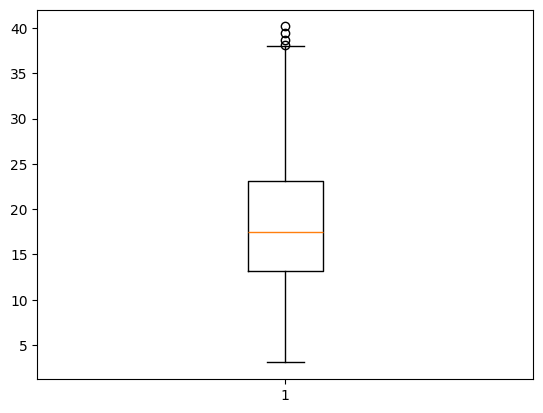

In [29]:
plt.boxplot(df1['total_bill'])

In [31]:
df1.shape

(235, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x1c0a869e210>,
 'caps': [<matplotlib.lines.Line2D at 0x1c0a869e490>,
 'boxes': [<matplotlib.lines.Line2D at 0x1c0a869e0d0>],
 'medians': [<matplotlib.lines.Line2D at 0x1c0a869e710>],
 'fliers': [<matplotlib.lines.Line2D at 0x1c0a869e850>],
 'means': []}

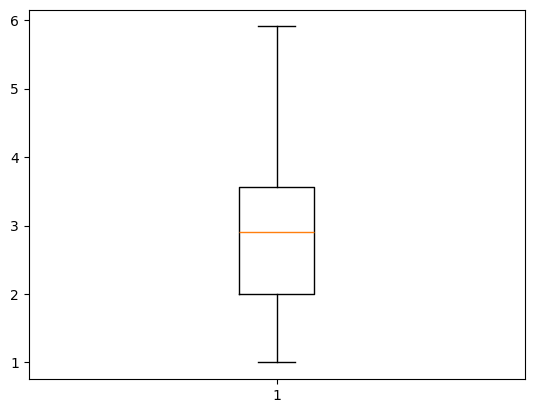

In [39]:
plt.boxplot(df['tip'])

In [35]:
q1 = df['tip'].quantile(0.25)
q3 = df['tip'].quantile(0.75)
iqr = q3-q1
print('iqr----', iqr)
lower = q1-1.5*iqr
print('lower------', lower)
upper = q3+1.5*iqr
print('upper----', iqr)


iqr---- 1.5625
lower------ -0.34375
upper---- 1.5625


In [43]:
df['tip']=df['tip'].clip(upper=upper)

{'whiskers': [<matplotlib.lines.Line2D at 0x1c0a924b110>,
 'caps': [<matplotlib.lines.Line2D at 0x1c0a924b390>,
 'boxes': [<matplotlib.lines.Line2D at 0x1c0a924afd0>],
 'medians': [<matplotlib.lines.Line2D at 0x1c0a924b610>],
 'fliers': [<matplotlib.lines.Line2D at 0x1c0a924b750>],
 'means': []}

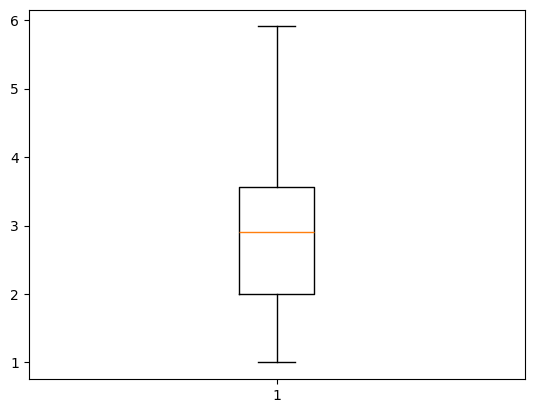

In [44]:
plt.boxplot(df['tip'])

In [45]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


In [46]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelBinarizer
from sklearn.compose import ColumnTransformer

In [48]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [51]:
num_fea=['total_bill']
ohe_fea=['sex','smoker']
min_max=['tip']

In [54]:
from sklearn.preprocessing import MinMaxScaler
transformer=ColumnTransformer(
transformers=[('num' , StandardScaler() , num_fea),
('min_max' , MinMaxScaler(), min_max),
('cat' , OneHotEncoder(drop='first') , ohe_fea) ,
], remainder='passthrough'
)

In [55]:
transformer.fit_transform(df)

array([[-0.3147113050904943, 0.002038216560509565, 0.0, ..., 'Sun',
        'Dinner', 2],
       [-1.0632353132988692, 0.13452229299363055, 1.0, ..., 'Sun',
        'Dinner', 3],
       [0.13777989987156145, 0.5095541401273886, 1.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.3246295019205694, 0.20382165605095542, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.2212865040659901, 0.15286624203821658, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.11322890288102155, 0.4076433121019109, 0.0, ..., 'Thur',
        'Dinner', 2]], dtype=object)

In [57]:
pd.DataFrame(transformer.fit_transform(df), columns=transformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.314711,0.002038,0.0,0.0,Sun,Dinner,2
1,-1.063235,0.134522,1.0,0.0,Sun,Dinner,3
2,0.13778,0.509554,1.0,0.0,Sun,Dinner,3
3,0.438315,0.470828,1.0,0.0,Sun,Dinner,2
4,0.540745,0.531975,0.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,1.0,1.0,0.0,Sat,Dinner,3
240,0.832275,0.203822,0.0,1.0,Sat,Dinner,2
241,0.32463,0.203822,1.0,1.0,Sat,Dinner,2
242,-0.221287,0.152866,1.0,0.0,Sat,Dinner,2
